# EDA propio de UNSW-NB15 — ¿qué podemos aprender antes de entrenar?

**Proyecto:** Defiende el servidor (MLOps) · **Datos:** solo el archivo de **entrenamiento** (175.341 conexiones).
**El test no se abre en este notebook**: queda reservado para la evaluación final.

Cada sección plantea una **pregunta**, la responde con un gráfico o una tabla y cierra con una **conclusión** y la
**decisión** que esa conclusión le impone al proyecto. Al final hay un resumen de las cinco conclusiones.

> Cómo reproducirlo: `python -m jupyter nbconvert --to notebook --execute notebooks/01_eda.ipynb`
> (necesita los CSV: `dvc pull` o los `curl` del README). La carga verifica filas y SHA-256.

In [1]:
%matplotlib inline
import sys, pathlib
ROOT = pathlib.Path.cwd()
if not (ROOT / "params.yaml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from src.data import load_raw, feature_columns   # verifica 175.341 filas y el SHA-256

# Paleta validada (daltonismo y contraste): azul = normal, naranja = ataque
NORMAL, ATAQUE = "#2a78d6", "#eb6834"
INK, SOFT, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": SOFT, "xtick.color": SOFT, "ytick.color": SOFT,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "font.size": 10, "figure.dpi": 110,
})
miles = lambda n: f"{int(n):,}".replace(",", ".")
FUENTE = "Fuente: cálculo propio sobre las 175.341 filas de entrenamiento de UNSW-NB15."

df = load_raw("train")
y = df["label"]
FEATS = feature_columns(df)
CAT = ["proto", "service", "state"]
NUM = [c for c in FEATS if c not in CAT]
print(f"{miles(len(df))} filas · {len(FEATS)} predictoras ({len(NUM)} numéricas, {len(CAT)} categóricas)")
print("Excluidas como entrada: id (orden del archivo), label y attack_cat (respuestas).")
print("Celdas vacías (NaN):", int(df[FEATS].isna().sum().sum()))

175.341 filas · 42 predictoras (39 numéricas, 3 categóricas)
Excluidas como entrada: id (orden del archivo), label y attack_cat (respuestas).
Celdas vacías (NaN): 0


## 1. ¿Qué estamos intentando detectar y qué tan parejas están las clases?

Normal: 56.000 (31.9%)  ·  Ataque: 119.341 (68.1%)
Predecir SIEMPRE 'ataque' acierta el 68.06% de las veces y alarma el 100% de las conexiones normales.


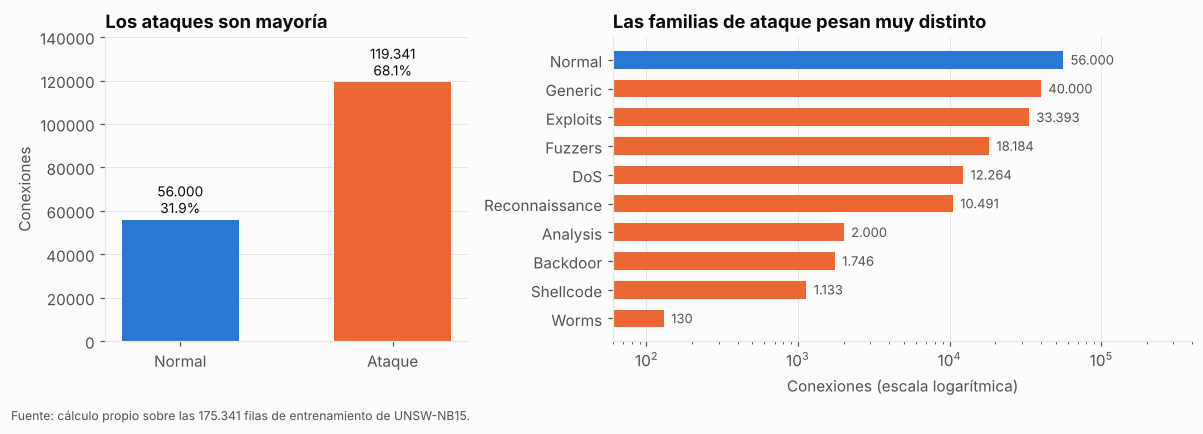

Worms: 130 ejemplos  vs  Generic: 40.000


In [2]:
n_norm, n_atk = int((y == 0).sum()), int((y == 1).sum())
fam = df["attack_cat"].value_counts()
print(f"Normal: {miles(n_norm)} ({n_norm/len(df):.1%})  ·  Ataque: {miles(n_atk)} ({n_atk/len(df):.1%})")
print(f"Predecir SIEMPRE 'ataque' acierta el {n_atk/len(df):.2%} de las veces y alarma el 100% de las conexiones normales.")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
a1.bar(["Normal", "Ataque"], [n_norm, n_atk], color=[NORMAL, ATAQUE], width=0.55)
for i, v in enumerate([n_norm, n_atk]):
    a1.text(i, v + 1500, f"{miles(v)}\n{v/len(df):.1%}", ha="center", va="bottom", fontsize=9)
a1.set_ylim(0, 140000); a1.set_title("Los ataques son mayoría"); a1.set_ylabel("Conexiones"); a1.grid(axis="x", visible=False)

orden = fam.sort_values()
cols = [NORMAL if k == "Normal" else ATAQUE for k in orden.index]
a2.barh(orden.index, orden.values, color=cols, height=0.62)
for i, v in enumerate(orden.values):
    a2.text(v * 1.12, i, miles(v), va="center", fontsize=8.5, color=SOFT)
a2.set_xscale("log"); a2.set_xlim(60, 400000)
a2.set_title("Las familias de ataque pesan muy distinto"); a2.set_xlabel("Conexiones (escala logarítmica)"); a2.grid(axis="y", visible=False)
fig.text(0.01, -0.02, FUENTE, fontsize=8, color=SOFT)
plt.tight_layout(); plt.show()
print("Worms:", fam["Worms"], "ejemplos  vs  Generic:", miles(fam["Generic"]))

**Conclusión 1 — La accuracy engaña.** El 68,06 % de las conexiones son ataques, así que un «modelo» que siempre diga *ataque* ya acierta 68 % y
no sirve de nada (alarma todo el tráfico normal). Además las familias son muy desiguales (Worms 130 ejemplos, Generic 40.000).
**Decisión:** evaluar con recall, precisión, tasa de falsos positivos y macro-F1; empezar por clasificación binaria.
Esa referencia trivial es el experimento E0.

## 2. ¿Los promedios describen bien estas medidas?

                media     mediana    percentil 99            máximo  máx / mediana
dur             1.359       0.002          45.353            60.000     37,926.668
sbytes      8,844.844     430.000      74,125.400    12,965,233.000     30,151.705
dbytes     14,928.919     164.000     474,367.800    14,655,550.000     89,363.110
sload  73,454,033.194 879,674.750 800,000,000.000 5,988,000,256.000      6,807.062
rate       95,406.187   3,225.807   1,000,000.003     1,000,000.003        310.000


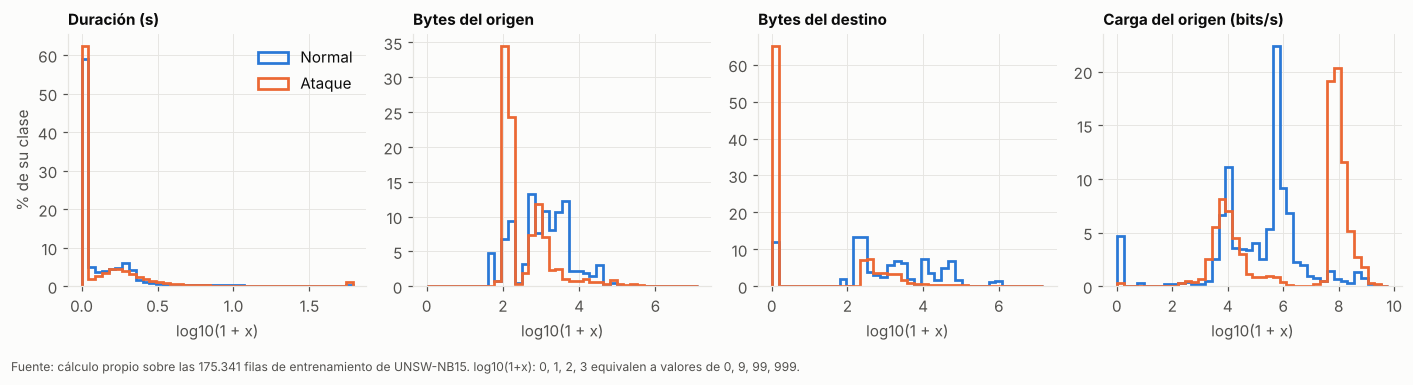

In [3]:
cols = ["dur", "sbytes", "dbytes", "sload", "rate"]
tab = pd.DataFrame({
    "media": df[cols].mean(), "mediana": df[cols].median(),
    "percentil 99": df[cols].quantile(0.99), "máximo": df[cols].max(),
})
tab["máx / mediana"] = tab["máximo"] / tab["mediana"]
print(tab.round(3).to_string(float_format=lambda v: f"{v:,.3f}"))

fig, axs = plt.subplots(1, 4, figsize=(13, 3.3), sharey=False)
for ax, c, t in zip(axs, ["dur", "sbytes", "dbytes", "sload"], ["Duración (s)", "Bytes del origen", "Bytes del destino", "Carga del origen (bits/s)"]):
    x = np.log10(1 + df[c].clip(lower=0))
    bins = np.linspace(0, x.max(), 41)
    for lab, color, name in [(0, NORMAL, "Normal"), (1, ATAQUE, "Ataque")]:
        v = x[y == lab]
        ax.hist(v, bins=bins, weights=np.ones(len(v)) / len(v) * 100, histtype="step", linewidth=1.8, color=color, label=name)
    ax.set_title(t, fontsize=10); ax.set_xlabel("log10(1 + x)")
axs[0].set_ylabel("% de su clase"); axs[0].legend(frameon=False, loc="upper right")
fig.text(0.01, -0.04, FUENTE + " log10(1+x): 0, 1, 2, 3 equivalen a valores de 0, 9, 99, 999.", fontsize=8, color=SOFT)
plt.tight_layout(); plt.show()

**Conclusión 2 — Las colas largas dominan los promedios.** En `sbytes` la mediana es 430 bytes, el percentil 99 pasa de 74.000 y el máximo supera
12,9 millones: la media dice poco de la conexión típica. En escala logarítmica las dos clases tienen formas distintas pero **se solapan**: ninguna de estas variables separa sola.
**Decisión:** resumir con mediana y percentiles; tratar la transformación log(1+x) como **hipótesis de experimento** (E2 contra E1), no como verdad.

## 3. ¿Hay filas repetidas y qué implican para validar?

Patrones distintos: 101.040  ·  repeticiones adicionales: 74.301 (42.4%)
Filas dentro de grupos repetidos (incluye la primera aparición): 84.049 (47.9%)
Grupos con entradas idénticas y etiqueta normal Y ataque a la vez: 229
Tasa de ataque entre filas repetidas: 92.8%  ·  entre filas únicas: 45.3%


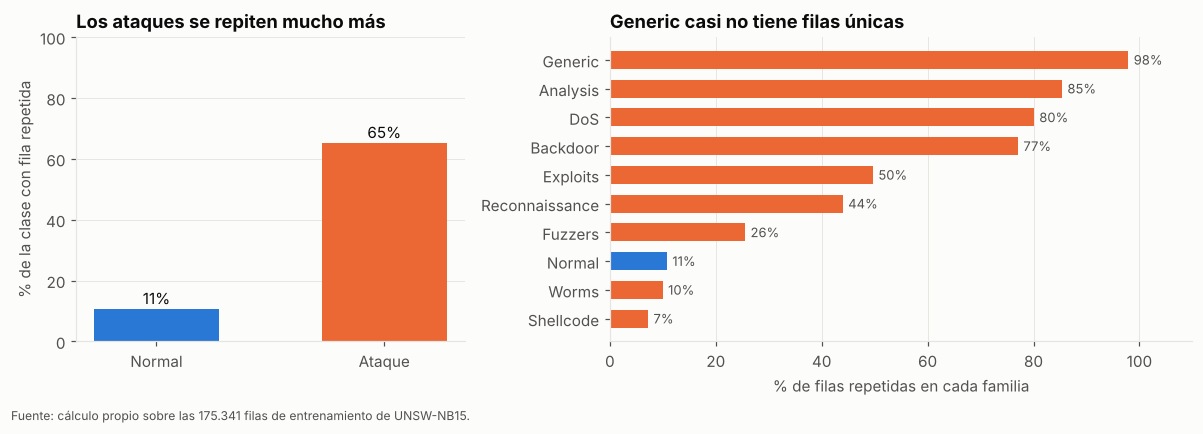

In [4]:
h = pd.util.hash_pandas_object(df[FEATS], index=False)       # el vector de entrada sin id ni respuestas
tam = h.map(h.value_counts())
rep = tam > 1                                               # fila que pertenece a un grupo con >1 filas iguales
print(f"Patrones distintos: {miles(h.nunique())}  ·  repeticiones adicionales: {miles(len(df) - h.nunique())} ({(len(df)-h.nunique())/len(df):.1%})")
print(f"Filas dentro de grupos repetidos (incluye la primera aparición): {miles(rep.sum())} ({rep.mean():.1%})")
conf = df.groupby(h.values)["label"].nunique()
print(f"Grupos con entradas idénticas y etiqueta normal Y ataque a la vez: {int((conf > 1).sum())}")

por_clase = rep.groupby(y).mean() * 100
por_fam = (rep.groupby(df["attack_cat"]).mean() * 100).sort_values()
tasa_rep, tasa_uni = y[rep].mean() * 100, y[~rep].mean() * 100
print(f"Tasa de ataque entre filas repetidas: {tasa_rep:.1f}%  ·  entre filas únicas: {tasa_uni:.1f}%")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.5]})
a1.bar(["Normal", "Ataque"], [por_clase[0], por_clase[1]], color=[NORMAL, ATAQUE], width=0.55)
for i, v in enumerate([por_clase[0], por_clase[1]]):
    a1.text(i, v + 1.5, f"{v:.0f}%", ha="center", fontsize=10)
a1.set_ylim(0, 100); a1.set_ylabel("% de la clase con fila repetida"); a1.set_title("Los ataques se repiten mucho más"); a1.grid(axis="x", visible=False)
cols_f = [NORMAL if k == "Normal" else ATAQUE for k in por_fam.index]
a2.barh(por_fam.index, por_fam.values, color=cols_f, height=0.62)
for i, v in enumerate(por_fam.values):
    a2.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8.5, color=SOFT)
a2.set_xlim(0, 110); a2.set_xlabel("% de filas repetidas en cada familia"); a2.set_title("Generic casi no tiene filas únicas"); a2.grid(axis="y", visible=False)
fig.text(0.01, -0.02, FUENTE, fontsize=8, color=SOFT)
plt.tight_layout(); plt.show()

**Conclusión 3 — Las repeticiones son un riesgo de fuga y no están repartidas al azar.** 74.301 filas (42,4 %) repiten un vector de entrada, y repetir es mucho más común en los ataques (65 %)
que en el tráfico normal (11 %). Si el mismo patrón cae en entrenamiento y en validación, el modelo lo *memoriza* y la validación sale inflada. Además hay 229 patrones con etiquetas contradictorias:
parte del error es irreducible con estas variables.
**Decisión:** separar entrenamiento y validación **agrupando por patrón** (`StratifiedGroupKFold`, 0 patrones compartidos); no borrar duplicados, documentarlo.

## 4. ¿Dónde está la señal y cómo tratar las variables categóricas y las «ausencias»?

Menos informativas por sí solas: ct_ftp_cmd (0.50), is_ftp_login (0.50), trans_depth (0.51), ct_flw_http_mthd (0.51), response_body_len (0.52)


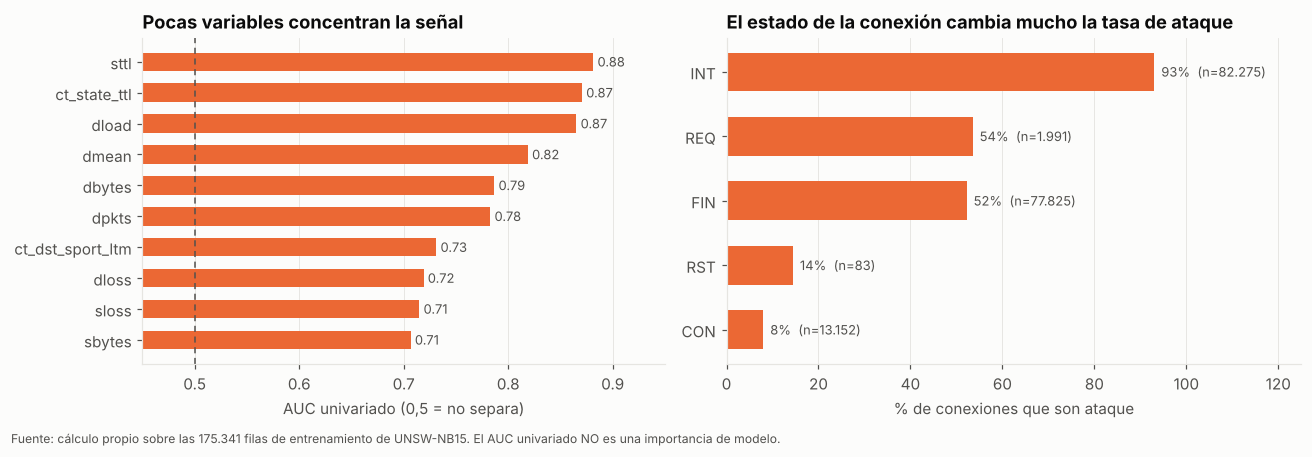

proto tiene 133 categorías; 31 tienen menos de 100 filas y suman 1.6% de los datos.
        size  tasa_ataque
proto                    
tcp    79946         51.1
udp    63283         78.0
unas   12084        100.0
arp     2859          0.0
ospf    2595         97.5
sctp    1150        100.0

service = '-' : 53.7% de las filas (no es NaN) · tasa de ataque 61.2%
dbytes = 0    : 48.1% de las filas · tasa de ataque 92.1%  (con dbytes>0: 45.8%)


In [5]:
auc = pd.Series({c: roc_auc_score(y, df[c]) for c in NUM})
auc = auc.map(lambda a: max(a, 1 - a)).sort_values()          # 0,5 = esa variable sola no separa
top, bajo = auc.tail(10), auc.head(5)
print("Menos informativas por sí solas:", ", ".join(f"{k} ({v:.2f})" for k, v in bajo.items()))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.1]})
a1.barh(top.index, top.values, color=ATAQUE, height=0.6)
for i, v in enumerate(top.values):
    a1.text(v + 0.004, i, f"{v:.2f}", va="center", fontsize=8.5, color=SOFT)
a1.axvline(0.5, color=SOFT, lw=1, ls=(0, (4, 3))); a1.set_xlim(0.45, 0.95)
a1.set_title("Pocas variables concentran la señal"); a1.set_xlabel("AUC univariado (0,5 = no separa)"); a1.grid(axis="y", visible=False)

est = df.groupby("state")["label"].agg(["mean", "size"]).query("size >= 80").sort_values("mean")
a2.barh(est.index, est["mean"] * 100, color=ATAQUE, height=0.6)
for i, (m, s) in enumerate(zip(est["mean"] * 100, est["size"])):
    a2.text(m + 1.5, i, f"{m:.0f}%  (n={miles(s)})", va="center", fontsize=8.5, color=SOFT)
a2.set_xlim(0, 125); a2.set_title("El estado de la conexión cambia mucho la tasa de ataque"); a2.set_xlabel("% de conexiones que son ataque"); a2.grid(axis="y", visible=False)
fig.text(0.01, -0.02, FUENTE + " El AUC univariado NO es una importancia de modelo.", fontsize=8, color=SOFT)
plt.tight_layout(); plt.show()

proto = df.groupby("proto")["label"].agg(["mean", "size"]).sort_values("size", ascending=False)
print(f"proto tiene {len(proto)} categorías; {int((proto['size'] < 100).sum())} tienen menos de 100 filas y suman {proto[proto['size']<100]['size'].sum()/len(df):.1%} de los datos.")
print(proto.head(6).assign(tasa_ataque=lambda t: (t['mean']*100).round(1))[["size", "tasa_ataque"]].to_string())
print()
print(f"service = '-' : {(df.service=='-').mean():.1%} de las filas (no es NaN) · tasa de ataque {y[df.service=='-'].mean():.1%}")
print(f"dbytes = 0    : {(df.dbytes==0).mean():.1%} de las filas · tasa de ataque {y[df.dbytes==0].mean():.1%}  (con dbytes>0: {y[df.dbytes>0].mean():.1%})")

**Conclusión 4 — La señal está concentrada, las categorías no son magnitudes y las «ausencias» informan.** `sttl` (0,88), `ct_state_ttl` (0,87) y `dload` (0,87) separan mejor que el resto; varias variables
casi no aportan solas (`is_ftp_login`, `ct_ftp_cmd`, ≈0,50). Las categóricas mezclan ambas clases (en `proto`: `arp` 0 % de ataque, `unas` y `sctp` 100 %, `tcp` 51 %). Lo que parece un valor vacío
dice algo: `service = «-»` cubre el 53,7 % de las filas sin ser NaN, y las conexiones **sin bytes de vuelta (`dbytes = 0`) son ataque el 92 %** de las veces (frente a 46 %).
**Decisión:** one-hot para `proto`/`service`/`state`; agrupar categorías raras (31 de 133 protocolos tienen <100 filas) y mapear las desconocidas a «infrecuente»; **no imputar ni borrar** «-» ni los ceros.

## 5. ¿Hay atajos de laboratorio que podrían inflar la validación?

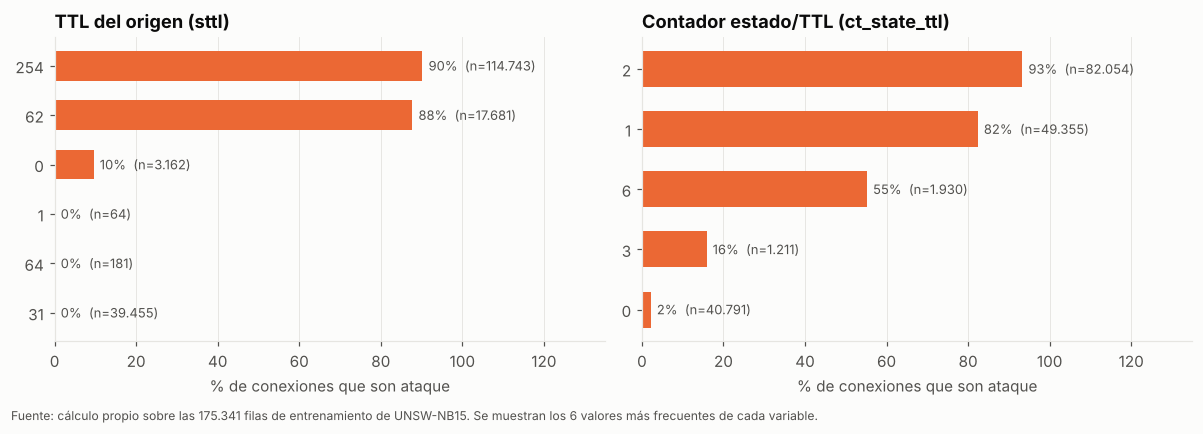

sttl = 31: 39.455 filas (22.5%) y tasa de ataque 0.0%
sttl = 254: 114.743 filas y tasa de ataque 90.2%


In [6]:
def tasa(col, k=6):
    t = df.groupby(col)["label"].agg(["mean", "size"]).sort_values("size", ascending=False).head(k).sort_values("mean")
    return t

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, ttl in [(a1, "sttl", "TTL del origen (sttl)"), (a2, "ct_state_ttl", "Contador estado/TTL (ct_state_ttl)")]:
    t = tasa(col)
    ax.barh(t.index.astype(str), t["mean"] * 100, color=ATAQUE, height=0.6)
    for i, (m, s) in enumerate(zip(t["mean"] * 100, t["size"])):
        ax.text(m + 1.5, i, f"{m:.0f}%  (n={miles(s)})", va="center", fontsize=8.5, color=SOFT)
    ax.set_xlim(0, 135); ax.set_title(ttl); ax.set_xlabel("% de conexiones que son ataque"); ax.grid(axis="y", visible=False)
fig.text(0.01, -0.02, FUENTE + " Se muestran los 6 valores más frecuentes de cada variable.", fontsize=8, color=SOFT)
plt.tight_layout(); plt.show()
s31 = df[df.sttl == 31]
print(f"sttl = 31: {miles(len(s31))} filas ({len(s31)/len(df):.1%}) y tasa de ataque {s31.label.mean():.1%}")
print(f"sttl = 254: {miles((df.sttl==254).sum())} filas y tasa de ataque {df[df.sttl==254].label.mean():.1%}")

**Conclusión 5 — Algunas variables parecen «atajos» del laboratorio.** Con `sttl = 31` hay 39.455 conexiones y **ninguna** es ataque; con `sttl = 254`, el 90 % lo es. En un laboratorio sintético esos valores pueden
reflejar *cómo se generó* el tráfico (qué máquinas actuaron) más que una propiedad del ataque. **No está demostrado**: es una hipótesis. Si es cierta, un modelo que se apoye en ellos puede lucir muy bien
en validación y peor en datos con otra distribución.
**Decisión:** no quitar la variable por intuición (se mantiene y se discute), pero **no confiar ciegamente en la validación**, reportar errores por grupo y dejar el test para una sola evaluación.
(En el proyecto el test salió peor que la validación; este patrón es una de las explicaciones posibles, sin probar.)

## Resumen: cinco conclusiones y la decisión que cada una impone

| # | Conclusión (evidencia) | Decisión en el proyecto |
|---|---|---|
| 1 | La accuracy engaña: «siempre ataque» acierta 68,06 % y alarma el 100 % de lo normal | Macro-F1, recall, precisión y tasa de falsos positivos; baseline E0 |
| 2 | Colas largas: `sbytes` mediana 430 B vs máximo > 12,9 M; las clases se solapan | Mediana/percentiles; log(1+x) como hipótesis (E2 vs E1) |
| 3 | 42,4 % de filas repetidas, más en ataques (65 % vs 11 %); 229 patrones contradictorios | Partición agrupada por patrón; 0 patrones compartidos; no borrar duplicados |
| 4 | Señal concentrada (`sttl`, `ct_state_ttl`, `dload`); categorías mezclan clases; `dbytes=0` → 92 % ataque; `service="-"` no es NaN | One-hot con categorías raras agrupadas; no imputar «-» ni ceros |
| 5 | `sttl=31` → 0 % ataque (39.455 filas): posible atajo del laboratorio | No fiarse solo de la validación; análisis de errores; test una sola vez |

**Límites de este EDA:** solo entrenamiento; asociaciones, no causas; el dataset preparado no trae `Stime`/`Ltime`, así que no se puede validar cronológicamente.